### ASTR 8070: Astrostatistics
***N. Pol***
___

# Homework 4
### Due: Wednesday, Oct. 14 11.59pm CST
---

## Problem 1

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_1.npy`. This is a (10 x 2) numpy array, with voltage measurements in the first column and heteroscedastic voltage uncertainties in the second column. Compute the sample mean and the standard error on the sample mean for this data.

2) Fit the appropriate ln-likelihood function and find the best-fit mean voltage.

3) Compute and plot the Bayesian posterior probability density (*not the log posterior*) for the mean voltage assuming a uniform prior for the mean in the range 3 to 7. Make sure this posterior pdf is normalized!

4) By either drawing samples from this posterior, or using your gridded posterior pdf to make a cdf, find the equal-tailed 68.3% credible region for the mean, and compare the upper and lower boundaries to the sample mean plus/minus the standard error, respectively. *Also* find the MAP value of the mean.

5) Repeat (3) and (4) this time with a prior on the mean that is uniform in the range 4.6 to 5.4. 

6) Now, imagine that we read an old paper about the experiment that gave us the voltage measurements, and they found that the mean was actually $6\pm0.3$. Repeat (3) and (4) this time with a Gaussian prior on the mean centered at $6$ with standard deviation of $0.3$.

7) Plot all of the normalized posterior pdfs for $\mu$ from (3), (5), and (6) on the same plot, making sure that the xlim of the plot spans 0 to 10.

8) You have made sure that the posterior pdfs are properly normalized, but until now you have ignored the meaning of that normalization constant. It is the Bayesian evidence for the particular model you have applied! Compute the evidence under a new model where the prior for the mean is a delta function at the best-fit value you found in (1) *(think about this and don't just immediately go looking for a `scipy.stats` delta function)*. Compare this to the evidence found under the prior in (3). Taking ratios to make a Bayes factor, which model is favored? Is there much of an Occam penalty by having the wide prior compared to knowing the mean exactly? 

### Solution

In [1]:
import numpy as np

data1 = np.load('/Users/jhorna/astrostats_ttu_fall26/coursework/homeworks/hw_data/hw4_data_1.npy')

voltage = data1[:, 0]
uncertainties = data1[:, 1]

mean = np.mean(voltage)
sigma = np.sqrt(np.sum(uncertainties**2)) / len(voltage)

print("Sample mean:", mean)
print("Standard error on the sample mean:", sigma)

Sample mean: 5.106
Standard error on the sample mean: 0.5247504168650083


In [2]:
from scipy.optimize import minimize_scalar

def log_likelihood(mu):
    return -0.5 * np.sum((voltage - mu)**2 / uncertainties**2+ np.log(2 * np.pi * uncertainties**2))

best_mu = minimize_scalar(lambda mu: -log_likelihood(mu)).x

print("Best-fit mean voltage:", best_mu)

Best-fit mean voltage: 4.942118214425292


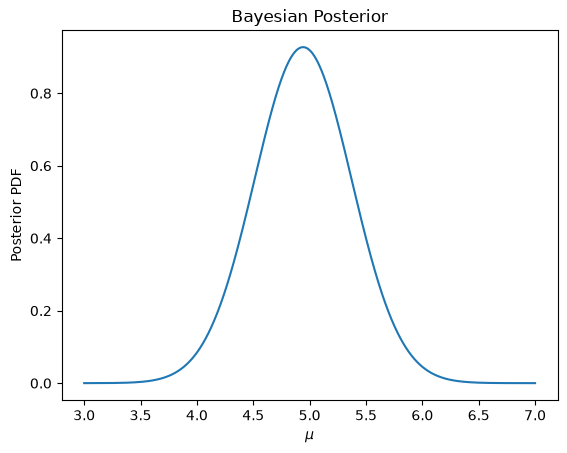

In [3]:
import matplotlib.pyplot as plt

mu_grid = np.linspace(3, 7, 1000)

def prior(mu):
    if 3 <= mu <= 7:
        return 1/4
    return 0
  
posterior = np.array([np.exp(log_likelihood(mu)) * prior(mu)
    for mu in mu_grid])

posterior /= np.trapezoid(posterior, mu_grid)

plt.plot(mu_grid, posterior)
plt.xlabel(r'$\mu$')
plt.ylabel('Posterior PDF')
plt.title('Bayesian Posterior')
plt.show()

To verify normalization

In [4]:
print(np.trapezoid(posterior, mu_grid))

1.0


In [5]:
from scipy.integrate import cumulative_trapezoid

cdf = cumulative_trapezoid(posterior, mu_grid, initial=0)

lower = np.interp(0.1585, cdf, mu_grid)
upper = np.interp(0.8415, cdf, mu_grid)

MAP = mu_grid[np.argmax(posterior)]

print("68.3% credible interval:", lower, upper)
print("MAP:", MAP)
print("Sample mean ± SE:", mean - sigma, mean + sigma)

68.3% credible interval: 4.511595485658871 5.3726449891640895
MAP: 4.941941941941942
Sample mean ± SE: 4.5812495831349915 5.630750416865008


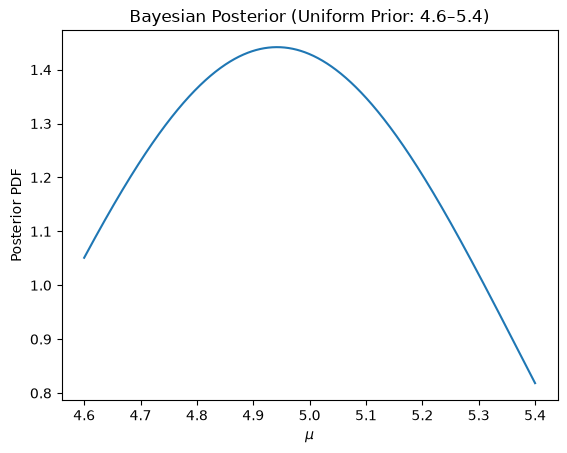

In [6]:
mu_grid2 = np.linspace(4.6, 5.4, 1000)

def prior2(mu):
    if 4.6 <= mu <= 5.4:
        return 1/0.8
    return 0

posterior2 = np.array([np.exp(log_likelihood(mu)) * prior2(mu)
                       for mu in mu_grid2])

posterior2 /= np.trapezoid(posterior2, mu_grid2)

plt.plot(mu_grid2, posterior2)
plt.xlabel(r'$\mu$')
plt.ylabel('Posterior PDF')
plt.title('Bayesian Posterior (Uniform Prior: 4.6–5.4)')
plt.show()

In [7]:
cdf2 = cumulative_trapezoid(posterior2, mu_grid2, initial=0)

lower2 = np.interp(0.1585, cdf2, mu_grid2)
upper2 = np.interp(0.8415, cdf2, mu_grid2)

MAP2 = mu_grid2[np.argmax(posterior2)]

print("68.3% credible interval:", lower2, upper2)
print("MAP:", MAP2)
print("Sample mean ± SE:", mean - sigma, mean + sigma)

68.3% credible interval: 4.735091951004752 5.238371073266267
MAP: 4.941941941941942
Sample mean ± SE: 4.5812495831349915 5.630750416865008


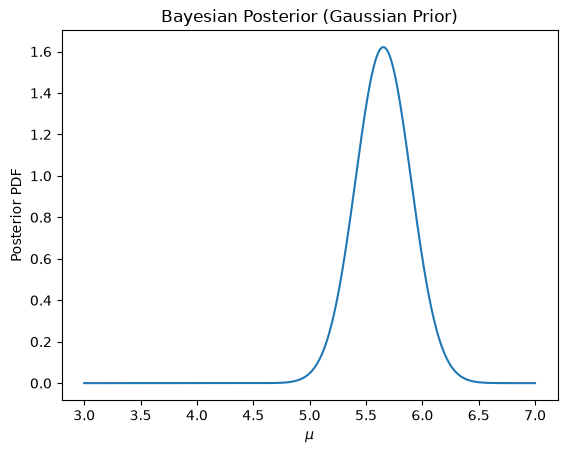

In [8]:
from scipy.stats import norm

mu_grid3 = np.linspace(3, 7, 1000)

def prior3(mu):
    return norm.pdf(mu, loc=6, scale=0.3)

posterior3 = np.array([np.exp(log_likelihood(mu) - log_likelihood(best_mu)) * prior3(mu)
                       for mu in mu_grid3])

posterior3 /= np.trapezoid(posterior3, mu_grid3)

plt.plot(mu_grid3, posterior3)
plt.xlabel(r'$\mu$')
plt.ylabel('Posterior PDF')
plt.title('Bayesian Posterior (Gaussian Prior)')
plt.show()

In [9]:
cdf3 = cumulative_trapezoid(posterior3, mu_grid3, initial=0)

lower3 = np.interp(0.1585, cdf3, mu_grid3)
upper3 = np.interp(0.8415, cdf3, mu_grid3)

MAP3 = mu_grid3[np.argmax(posterior3)]

print("68.3% credible interval:", lower3, upper3)
print("MAP:", MAP3)
print("Sample mean ± SE:", mean - sigma, mean + sigma)

68.3% credible interval: 5.407667680930829 5.900175821992837
MAP: 5.654654654654655
Sample mean ± SE: 4.5812495831349915 5.630750416865008


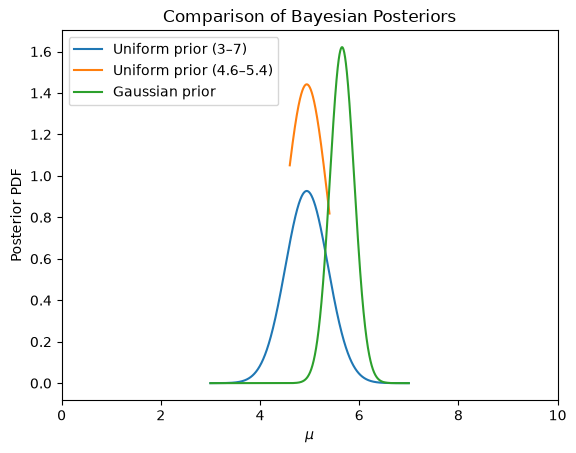

In [10]:
plt.plot(mu_grid, posterior, label='Uniform prior (3–7)')
plt.plot(mu_grid2, posterior2, label='Uniform prior (4.6–5.4)')
plt.plot(mu_grid3, posterior3, label='Gaussian prior')

plt.xlim(0, 10)
plt.xlabel(r'$\mu$')
plt.ylabel('Posterior PDF')
plt.title('Comparison of Bayesian Posteriors')
plt.legend()
plt.show()

In [11]:
Z1 = np.exp(log_likelihood(best_mu))

Z2 = np.trapezoid([np.exp(log_likelihood(mu)) / 4 for mu in mu_grid],mu_grid)

BF = Z1 / Z2

print("Delta prior evidence:", Z1)
print("Uniform prior evidence:", Z2)
print("Bayes factor:", BF)

Delta prior evidence: 1.0725971348964463e-07
Uniform prior evidence: 2.8918714337222733e-08
Bayes factor: 3.7090069855417207


The Bayes factor is approximately 3.71, which means the delta-prior model is favored over the wide uniform-prior model. The delta-prior model has about 3.71 times higher evidence.
The wide uniform prior has a moderate Occam penalty because it allows a larger range of mean values, including values that do not fit the data well.
Therefore, there is some Occam penalty, but it is not very large.

## Problem 2

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_2.npy`, which is a (3 x 20) numpy array that you used in `Lecture_9`. Set `x, y, sigma_y = data`. 

We're going to do some polynomial fits to this data just like in `Lecture 9`. However, in all cases you should **keep the $y$-intercept fixed at $-0.23$**. 

2) Use the following code to compute the un-normalized posterior pdf (i.e. just the likelihood x prior) on a grid of the linear coefficient (i.e. the slope) of a linear model, with a uniform prior between 0.5 and 1.5. Plot this posterior pdf. Remember this is just a one-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100.

In [34]:
data = np.load('/Users/jhorna/astrostats_ttu_fall26/coursework/homeworks/hw_data/hw4_data_2.npy')

x, y, sigma_y = data

print(data)

[[ 0.42  0.72  0.    0.3   0.15  0.09  0.19  0.35  0.4   0.54  0.42  0.69
   0.2   0.88  0.03  0.67  0.42  0.56  0.14  0.2 ]
 [ 0.33  0.41 -0.25  0.01 -0.05 -0.05 -0.12  0.26  0.29  0.39  0.31  0.42
  -0.01  0.58 -0.2   0.52  0.15  0.32 -0.13 -0.09]
 [ 0.1   0.1   0.1   0.1   0.1   0.1   0.1   0.1   0.1   0.1   0.1   0.1
   0.1   0.1   0.1   0.1   0.1   0.1   0.1   0.1 ]]


In [17]:
#Functions to do a polynomial fit, and compute the likelihood
import scipy
def polynomial_fit(theta, x):
    """Polynomial model of degree (len(theta) - 1)"""
    # For a polynomial with order 1, this gives theta_0 + theta_1*x
    # For a polynomial with order 2, this gives theta_0 + theta_1*x + theta_2*x^2, etc.
    return sum(t * x ** n for (n, t) in enumerate(theta))

# compute the data log-likelihood given a model
def logL(theta, data, model=polynomial_fit):
    """Gaussian log-likelihood of the model at theta"""
    x, y, sigma_y = data
    y_fit = model(theta, x)
    return sum(scipy.stats.norm.logpdf(*args) 
               for args in zip(y, y_fit, sigma_y))

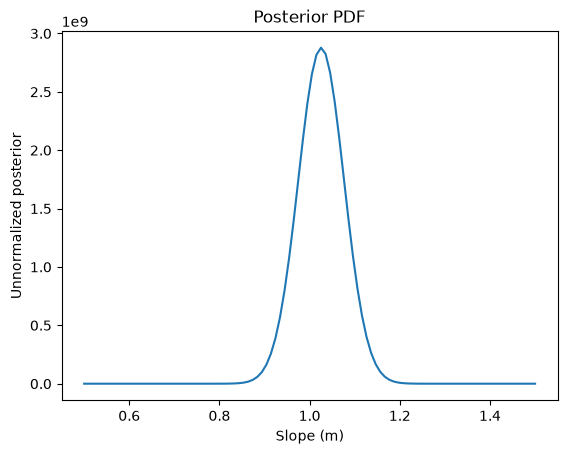

In [20]:
m_grid = np.linspace(0.5,1.5,100)

posterior = []

for m in m_grid:
    theta = [-0.23,m]
    likelihood = np.exp(logL(theta, data))
    prior = 1
    posterior.append(likelihood*prior)

posterior = np.array(posterior)

plt.plot(m_grid, posterior)
plt.xlabel("Slope (m)")
plt.ylabel("Unnormalized posterior")
plt.title("Posterior PDF")
plt.show()

3) Using your 1D gridded likelihood-x-prior, compute the Bayesian evidence of this linear model. This may be a big number!

4) Now compute the joint 2D posterior pdf (again just the likelihood x prior) of linear and quadratic coefficients of a quadratic model. Give the linear coefficient a uniform prior between 0.5 and 1.5. Give the quadratic coefficient a uniform prior between -1 and 0.25. Plot this two-dimensional posterior. Remember this is a two-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100 in each model dimension.

5) Using your 2D gridded likelihood-x-prior, compute the Bayesian evidence of the quadratic model. 

6) Calculate the Bayes factor for a linear versus quadratic model. How does this compare/contrast with the BIC model comparison in the lecture? 

### Solution

In [29]:
evid_linear = np.trapezoid(posterior, m_grid)

print("Bayesian Evidence (Linear):", evid_linear)

Bayesian Evidence (Linear): 365684733.16065943


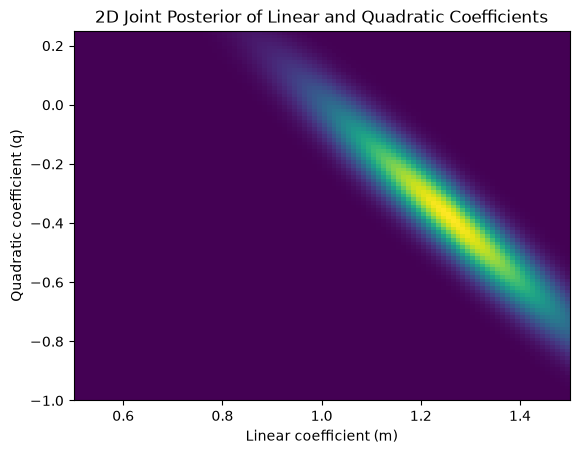

In [28]:
m_grid = np.linspace(0.5,1.5,100)
q_grid = np.linspace(-1,0.25,100)

posterior_2d = np.zeros((100,100))

for i, m in enumerate(m_grid):
    for j, q in enumerate(q_grid):
        theta = [-0.23,m,q]
        likelihood = np.exp(logL(theta, data))
        prior = 1/1.25
        posterior_2d[j,i] = likelihood*prior

plt.imshow(posterior_2d, origin='lower', extent=[0.5, 1.5, -1, 0.25], aspect='auto')
plt.xlabel('Linear coefficient (m)')
plt.ylabel('Quadratic coefficient (q)')
plt.title('2D Joint Posterior of Linear and Quadratic Coefficients')
plt.show()

In [30]:
evid_quad = np.trapezoid(np.trapezoid(posterior_2d, m_grid, axis =1), q_grid)

print("Bayesian Evidence (Quadratic):", evid_quad)

Bayesian Evidence (Quadratic): 490433690.6169992


In [33]:
BF = evid_linear / evid_quad
print("Bayes factor (linear vs quadratic):", BF)

if BF > 1:
    print("The linear model is favored.")
elif BF < 1:
    print("The quadratic model is favored.")
else:
    print("Neither model is favored.")

Bayes factor (linear vs quadratic): 0.7456354246393696
The quadratic model is favored.


The Bayes factor is approximately 0.746, which means the quadratic model is slightly preferred over the linear model. However, the BIC comparison in Lecture 9 slightly favors the linear model. Both methods consider how well the models fit the data and their complexity, but they do so differently. The Bayes factor uses the likelihood and prior distributions, while BIC includes a penalty for additional parameters. Also, the intercept is fixed in this homework but was estimated in Lecture 9, which may contribute to the difference in results.